# 01 · EDA de las notas por asignatura

**Bloque exploratorio** (antes de elegir el tema). Cuatro partes:

1. **Resultados publicados por la OCDE** (2000-2022, todos los países participantes): qué países participan en cada edición y cómo evolucionan sus notas.
2. **Notas medias por país y por centro** de los 33 países OCDE del proyecto (2012-2022), calculadas desde las tablas maestras. Las usan otros notebooks.
3. **Correlación entre asignaturas**: si matemáticas, lectura y ciencias ordenan a los alumnos de forma parecida.
4. **Reparto de la varianza de la nota** entre países, centros y alumnos.

## 0. Configuración

In [1]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.io as pio
import pyarrow.parquet as pq
import seaborn as sns

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.pisa_estadisticas import CLAVES_NIVEL, agregar_pv, centrar_en_grupos, estimar_con_pv, reparto_varianza
from src.pisa_pipeline import DOMINIOS, EDICIONES_PISA, columnas_pv, rutas_datos_anuales
from src.pisa_resultados_publicados import plot_comparar_paises, plot_comparar_paises_todas_materias, plot_evolucion_pais
from src.utils_pisa import establecer_semilla

establecer_semilla()
# Renderizador de VS Code: guarda solo los datos de cada figura (el notebook pesa poco) y VS Code las dibuja.
# 'notebook_connected' carga Plotly desde internet y VS Code no lo muestra
pio.renderers.default = 'vscode'

ruta_datos_raw = Path('../../data/raw')
ruta_medias_asignaturas = Path('../../data/intermediate') / 'medias_asignaturas_anual'
EDICIONES = [2012, 2015, 2018, 2022]
MEDIA_OCDE = 'International Average (OECD)'

Semillas del proyecto establecidas con éxito (seed=42).


## 1. Resultados publicados por la OCDE (2000-2022)

Ficheros `pisa_mathematics_2000_2022.csv`, `pisa_reading_2000_2022.csv` y `pisa_science_2000_2022.csv` de `data/raw`: una fila por país, edición y asignatura (`subject`), con la media, su error típico, la desviación típica y los percentiles 5 a 95 publicados por la OCDE. Incluyen todos los países participantes, no solo los 33 del proyecto, y la media OCDE (`International Average (OECD)`).

In [2]:
# Una tabla con las tres asignaturas
tablas_asignatura = []
for asignatura in ['mathematics', 'reading', 'science']:
    tabla = pd.read_csv(ruta_datos_raw / f'pisa_{asignatura}_2000_2022.csv')
    tabla['subject'] = asignatura
    tablas_asignatura.append(tabla)
resultados_ocde = pd.concat(tablas_asignatura, ignore_index=True)
resultados_ocde.columns.tolist()

['year',
 'country',
 'average',
 'standard_error',
 'std_dev',
 'std_dev_se',
 'p5',
 'p5_se',
 'p10',
 'p10_se',
 'p25',
 'p25_se',
 'p50',
 'p50_se',
 'p75',
 'p75_se',
 'p90',
 'p90_se',
 'p95',
 'p95_se',
 'subject']

In [3]:
# Algunos países tienen 2015 en una fila aparte, con el nombre «[país] (2015)»: por ejemplo, Argentina no tiene
# valores en 2015 y «Argentina (2015)» solo tiene 2015. Se quita el sufijo y se juntan: `.first()` coge el primer
# valor no nulo de cada columna
resultados_ocde['country'] = resultados_ocde['country'].str.replace(r' \(2015\)$', '', regex=True)
resultados_ocde = resultados_ocde.groupby(['country', 'year', 'subject'], as_index=False).first()

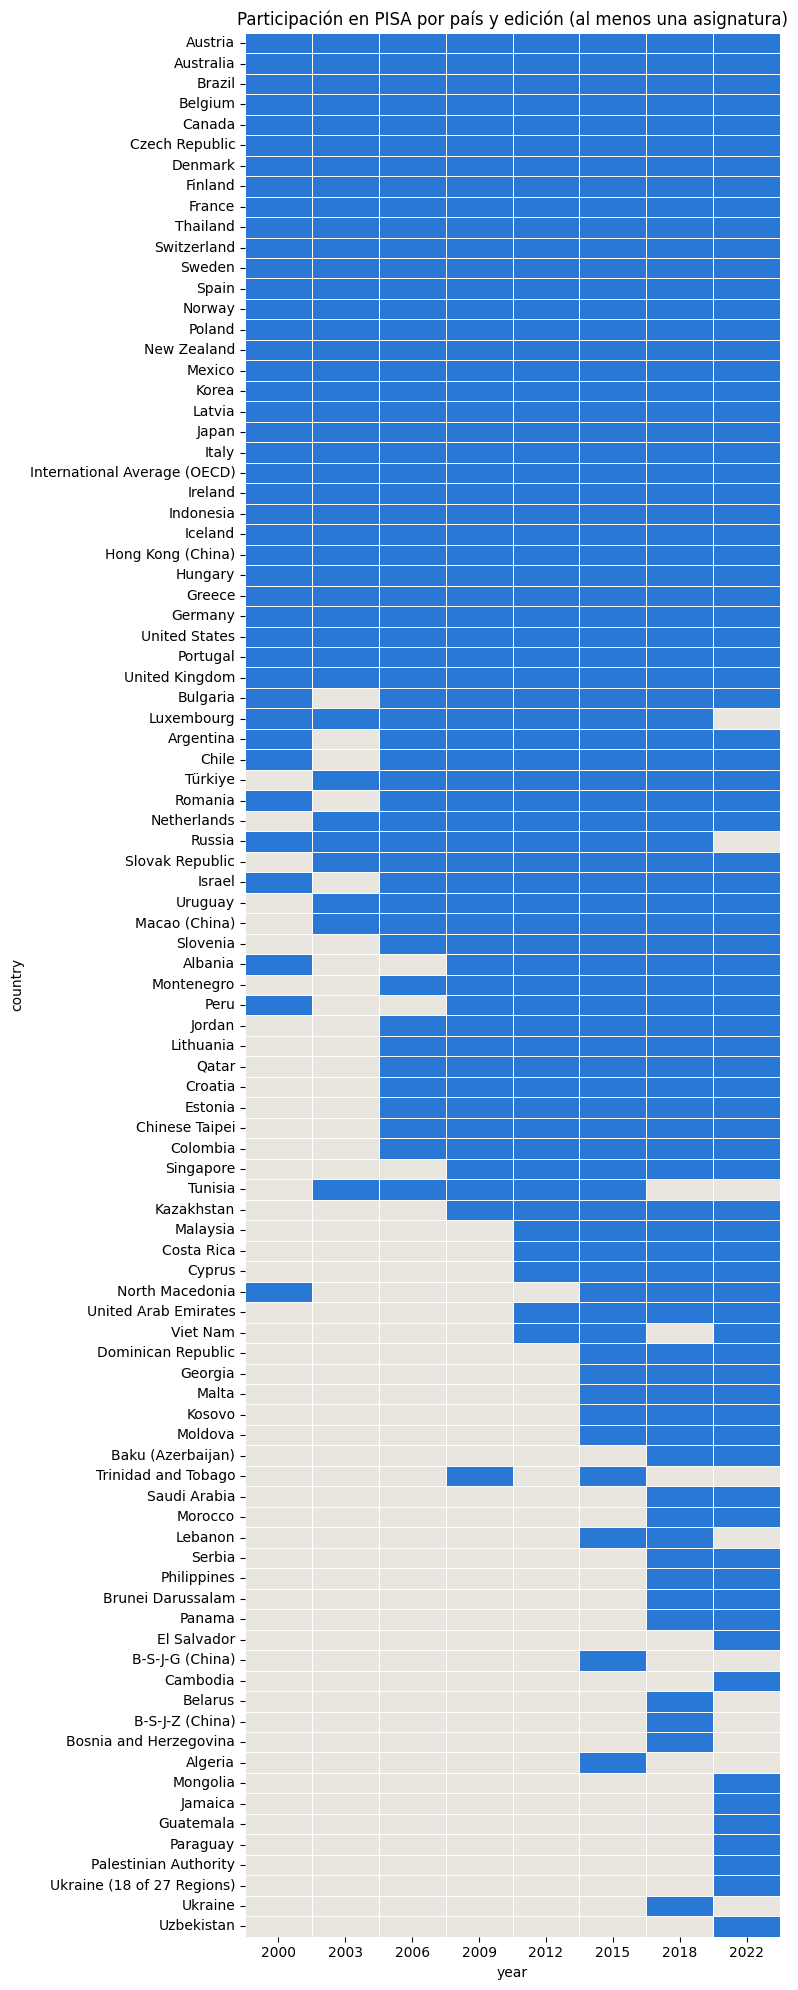

In [4]:
# Participación de cada país: si tiene dato en al menos una asignatura en cada edición
participacion = (resultados_ocde.pivot_table(index='country', columns='year', values='average', aggfunc='count')
                 .fillna(0).astype(bool).sort_index(axis=1))
participacion = participacion.loc[participacion.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 20))   # alto porque son ~90 países
sns.heatmap(participacion, cmap=['#e8e6df', '#2a78d6'], cbar=False, linewidths=0.5, linecolor='white', ax=ax)   # gris: no participó; azul: participó
ax.set_title('Participación en PISA por país y edición (al menos una asignatura)')
plt.tight_layout()
plt.show()

Muchos países, sobre todo los que no son de la OCDE, han participado en pocas ediciones y de forma irregular. Para las gráficas se conservan los que participaron en las cuatro últimas ediciones o en al menos seis (para verlos todos, basta con no ejecutar la celda siguiente).

In [5]:
ultimas_ediciones = participacion.columns[-4:]
paises_validos = participacion.index[participacion[ultimas_ediciones].all(axis=1) | (participacion.sum(axis=1) >= 6)]
resultados_ocde = resultados_ocde[resultados_ocde['country'].isin(paises_validos)]

paises_descartados = participacion.index.difference(paises_validos)
print(f'Se conservan {len(paises_validos.drop(MEDIA_OCDE))} países y la media OCDE; se descartan {len(paises_descartados)}:')
print(sorted(paises_descartados))

Se conservan 60 países y la media OCDE; se descartan 32:
['Algeria', 'B-S-J-G (China)', 'B-S-J-Z (China)', 'Baku (Azerbaijan)', 'Belarus', 'Bosnia and Herzegovina', 'Brunei Darussalam', 'Cambodia', 'Dominican Republic', 'El Salvador', 'Georgia', 'Guatemala', 'Jamaica', 'Kosovo', 'Lebanon', 'Malta', 'Moldova', 'Mongolia', 'Morocco', 'North Macedonia', 'Palestinian Authority', 'Panama', 'Paraguay', 'Philippines', 'Saudi Arabia', 'Serbia', 'Trinidad and Tobago', 'Tunisia', 'Ukraine', 'Ukraine (18 of 27 Regions)', 'Uzbekistan', 'Viet Nam']


### 1.1 Evolución de las notas

Gráficos interactivos (funciones de `src/pisa_resultados_publicados.py`): España en las tres asignaturas y su media; España frente a la media OCDE en el percentil 90 de matemáticas (el 10 % de alumnos con mejor nota); España frente a Portugal, Francia, Italia y Alemania; y cuatro países OCDE elegidos al azar (con la semilla fijada) junto a la media OCDE.

In [6]:
PAISES_OCDE = ['Australia', 'Austria', 'Belgium', 'Canada', 'Chile', 'Colombia', 'Costa Rica', 'Czech Republic', 'Denmark', 'Estonia',
               'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Japan', 'Korea', 'Latvia',
               'Lithuania', 'Luxembourg', 'Mexico', 'Netherlands', 'New Zealand', 'Norway', 'Poland', 'Portugal', 'Slovak Republic',
               'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Türkiye', 'United Kingdom', 'United States']

plot_evolucion_pais(resultados_ocde, 'Spain').show()

In [7]:
# La métrica es el percentil 90 (el 10 % de alumnos con mejor nota) en lugar de la media
plot_comparar_paises(df=resultados_ocde, paises=['Spain', MEDIA_OCDE], materia='mathematics', metrica='p90').show()

In [8]:
plot_comparar_paises_todas_materias(df=resultados_ocde, paises=['Spain', 'Portugal', 'France', 'Italy', 'Germany']).show()

In [9]:
paises_al_azar = random.sample(PAISES_OCDE, 4) + [MEDIA_OCDE]   # con la semilla de establecer_semilla()
plot_comparar_paises_todas_materias(resultados_ocde, paises_al_azar).show()

In [10]:
# Media de España y de la OCDE en cada asignatura, 2012-2022
(resultados_ocde[resultados_ocde['country'].isin(['Spain', MEDIA_OCDE]) & resultados_ocde['year'].isin(EDICIONES)]
 .pivot_table(index=['subject', 'country'], columns='year', values='average').round(1))

year                                       2012   2015   2018   2022
subject     country                                                 
mathematics International Average (OECD)  488.2  484.9  487.0  472.4
            Spain                         484.3  485.8  481.4  473.1
reading     International Average (OECD)  491.8  488.5  485.5  475.6
            Spain                         487.9  495.6    NaN  474.3
science     International Average (OECD)  496.4  488.8  486.7  484.6
            Spain                         496.4  492.8  483.3  484.5

**Qué se ve.** Se conservan 60 países y la media OCDE; se descartan 32 que participaron en pocas ediciones. La media OCDE baja entre 2012 y 2022 en las tres asignaturas, sobre todo en 2022: en matemáticas pasa de 488,2 a 472,4 puntos, en lectura de 491,8 a 475,6 y en ciencias de 496,4 a 484,6. España sigue de cerca a la media OCDE en todas las ediciones (en matemáticas, 484,3 en 2012 y 473,1 en 2022). España no tiene resultado de lectura en 2018: la OCDE no lo publicó.

## 2. Notas medias por país y por centro (2012-2022)

Nota media de cada asignatura (`MATH`, `READ`, `SCIE`) desde las tablas maestras de `00_pipeline_multiedicion_PISA`: se promedian los valores plausibles de cada alumno y se pondera por `W_FSTUWT` (`agregar_pv` de `src/pisa_estadisticas.py`). El centro se identifica con `CNT` + `CNTSCHID`, porque en 2012 `CNTSCHID` se repite entre países.

Se guardan en `data/intermediate/medias_asignaturas_anual/` (`pisa_medias_asignaturas_pais_anual.parquet` y `pisa_medias_asignaturas_centro_anual.parquet`). Las usan `01_EDA_factores_macroeconomicos`, `01_EDA_equidad` y `01_EDA_indice_de_compromiso_competencia`.

In [11]:
# Nota media de cada asignatura por país y por centro, en cada edición
medias_por_nivel = {'pais': [], 'centro': []}
for edicion in EDICIONES:
    ruta_estudiantes, _ = rutas_datos_anuales(str(ruta_datos_raw), edicion)
    columnas_pv_edicion = [columna for columna in pq.ParquetFile(ruta_estudiantes).schema.names
                           if any(columna in columnas_pv(dominio) for dominio in DOMINIOS)]
    alumnos = pd.read_parquet(ruta_estudiantes, columns=['CNT', 'CNTSCHID', 'W_FSTUWT'] + columnas_pv_edicion)
    for nivel, tablas in medias_por_nivel.items():
        medias_edicion = None
        for dominio in DOMINIOS:
            media = agregar_pv(alumnos, dominio, nivel, nombre=f'media_{dominio.lower()}_{nivel}')
            medias_edicion = media if medias_edicion is None else medias_edicion.merge(media, on=CLAVES_NIVEL[nivel], validate='one_to_one')
        tablas.append(medias_edicion.assign(year=edicion))

medias_pais = pd.concat(medias_por_nivel['pais'], ignore_index=True).sort_values(['year', 'CNT'], ascending=False, ignore_index=True)
medias_centro = pd.concat(medias_por_nivel['centro'], ignore_index=True).sort_values(['year', 'CNT', 'CNTSCHID'], ascending=False, ignore_index=True)

medias_pais.to_parquet(ruta_medias_asignaturas / 'pisa_medias_asignaturas_pais_anual.parquet', index=False)
medias_centro.to_parquet(ruta_medias_asignaturas / 'pisa_medias_asignaturas_centro_anual.parquet', index=False)
print(f'medias por país: {medias_pais.shape} | por centro: {medias_centro.shape} -> {ruta_medias_asignaturas}')
print('centros por edición:', medias_centro.groupby('year').size().to_dict())
medias_centro.head()

medias por país: (132, 5) | por centro: (41298, 6) -> ..\..\data\intermediate\medias_asignaturas_anual
centros por edición: {2012: 11725, 2015: 9076, 2018: 10366, 2022: 10131}


,CNT,CNTSCHID,media_math_centro,media_read_centro,media_scie_centro,year
0,USA,84000163,388.667326,406.987893,413.315619,2022
1,USA,84000162,527.321790,540.685498,575.180552,2022
2,USA,84000161,385.266026,420.096352,407.733427,2022
3,USA,84000160,492.090707,528.801348,524.854801,2022
4,USA,84000159,492.248879,545.676243,531.463219,2022


## 3. Correlación entre asignaturas

Si las tres notas ordenan a los alumnos casi igual, analizar una sola asignatura basta. Correlación entre las notas de matemáticas, lectura y ciencias de cada alumno, dentro de su país (cada nota centrada en la media de su país, con `SENWT`), en cada edición. Se calcula con cada valor plausible (el mismo número en las tres asignaturas) y se promedian las correlaciones (`estimar_con_pv`).

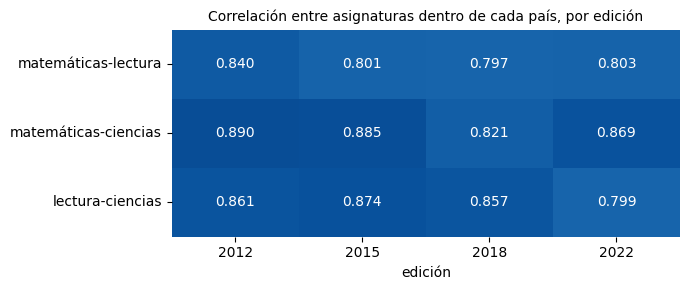

In [12]:
def correlaciones_asignaturas(datos, columna_matematicas):
    """Correlaciones dentro de cada país entre las tres asignaturas, con el valor plausible `columna_matematicas` y los del mismo número en lectura y ciencias."""
    columnas = [columna_matematicas.replace('MATH', dominio) for dominio in DOMINIOS]
    centradas = centrar_en_grupos(datos, columnas, ['CNT'], peso_col='SENWT')
    return centradas.rename(columns=lambda columna: columna.replace(columna_matematicas.replace('MATH', ''), '')).corr()


correlaciones = {}
for edicion in EDICIONES:
    ruta_estudiantes, _ = rutas_datos_anuales(str(ruta_datos_raw), edicion)
    columnas_parquet = pq.ParquetFile(ruta_estudiantes).schema.names
    alumnos = pd.read_parquet(ruta_estudiantes, columns=['CNT', 'SENWT'] + [columna for dominio in DOMINIOS for columna in columnas_pv(dominio) if columna in columnas_parquet])
    matriz = estimar_con_pv(alumnos, 'MATH', correlaciones_asignaturas)
    correlaciones[edicion] = {'matemáticas-lectura': matriz.loc['MATH', 'READ'], 'matemáticas-ciencias': matriz.loc['MATH', 'SCIE'], 'lectura-ciencias': matriz.loc['READ', 'SCIE']}
correlaciones = pd.DataFrame(correlaciones)

fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(correlaciones, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title('Correlación entre asignaturas dentro de cada país, por edición', fontsize=10)
ax.set_xlabel('edición')
plt.tight_layout()
plt.show()

**Qué se ve.** Las tres asignaturas están muy correlacionadas dentro de cada país: entre 0,797 y 0,840 matemáticas con lectura, entre 0,821 y 0,890 matemáticas con ciencias y entre 0,799 y 0,874 lectura con ciencias, según la edición. Un alumno con buena nota en una asignatura suele tenerla en las otras, así que el análisis se centra en matemáticas sin perder mucho.

## 4. Reparto de la varianza de la nota

Reparto de la varianza de la nota entre países, entre centros de un mismo país y entre alumnos de un mismo centro, en cada edición y asignatura (sumas de cuadrados anidadas, `reparto_varianza` de `src/pisa_estadisticas.py`):

* **Ponderado con `SENWT`**: cada país pesa igual (5.000), así que el reparto no depende del tamaño de su muestra.
* **Con cada valor plausible por separado**: se reparte la varianza de cada uno y se promedian los porcentajes (10 valores plausibles; 5 en 2012). Promediar antes los valores plausibles de cada alumno reduciría la variación entre alumnos.
* **Las tres asignaturas en todas las ediciones**, para que las cifras se puedan comparar entre ediciones. La tabla marca el dominio principal de cada edición (el que tiene más preguntas).

Es un reparto descriptivo: en los centros con pocos alumnos evaluados, la media del centro tiene ruido de muestreo, que infla algo la parte entre centros.

In [13]:
# Reparto de la varianza de cada valor plausible (ponderado con SENWT); los porcentajes son la media de los de cada uno
niveles_alumnos = {'entre países': CLAVES_NIVEL['pais'], 'entre centros (dentro del país)': CLAVES_NIVEL['centro']}
filas_varianza = []
for edicion in EDICIONES:
    ruta_estudiantes, _ = rutas_datos_anuales(str(ruta_datos_raw), edicion)
    columnas_parquet = pq.ParquetFile(ruta_estudiantes).schema.names
    pv_por_dominio = {dominio: [columna for columna in columnas_pv(dominio) if columna in columnas_parquet] for dominio in DOMINIOS}
    alumnos = pd.read_parquet(ruta_estudiantes, columns=['CNT', 'CNTSCHID', 'SENWT'] + [columna for columnas in pv_por_dominio.values() for columna in columnas])
    for dominio, columnas_dominio in pv_por_dominio.items():
        reparto_medio = pd.DataFrame([reparto_varianza(alumnos, columna, niveles_alumnos, 'entre alumnos (dentro del centro)', peso_col='SENWT')
                                      for columna in columnas_dominio]).mean()
        filas_varianza.append({'edición': edicion, 'asignatura': dominio, 'dominio principal': 'sí' if dominio == EDICIONES_PISA[edicion]['dominio_principal'] else '',
                               **reparto_medio.to_dict(), 'valores plausibles': len(columnas_dominio)})
varianza_por_edicion = pd.DataFrame(filas_varianza).set_index(['edición', 'asignatura'])
varianza_por_edicion.round(1)

dominio principal  entre países  \
edición asignatura                                   
2012    MATH                      sí           9.3   
        READ                                   6.0   
        SCIE                                   8.7   
2015    MATH                                   9.2   
        READ                                   6.2   
        SCIE                      sí           8.1   
2018    MATH                                   8.1   
        READ                      sí           4.8   
        SCIE                                   6.2   
2022    MATH                      sí           8.1   
        READ                                   5.2   
        SCIE                                   6.6   

                    entre centros (dentro del país)  \
edición asignatura                                    
2012    MATH                                   36.1   
        READ                                   38.0   
        SCIE                                   34.6   
2015    MATH                                   31.4   
        READ                                   33.0   
        SCIE                                   31.2   
2018    MATH                                   32.2   
        READ                                   32.0   
        SCIE                                   31.4   
2022    MATH                                   32.5   
        READ                                   30.6   
        SCIE                                   30.5   

                    entre alumnos (dentro del centro)  valores plausibles  
edición asignatura                                                         
2012    MATH                                     54.6                   5  
        READ                                     56.0                   5  
        SCIE                                     56.7                   5  
2015    MATH                                     59.4                  10  
        READ                                     60.9                  10  
        SCIE                                     60.7                  10  
2018    MATH                                     59.7                  10  
        READ                                     63.2                  10  
        SCIE                                     62.4                  10  
2022    MATH                                     59.3                  10  
        READ                                     64.2                  10  
        SCIE                                     62.8                  10

**Qué se ve.**

* **La mayor parte de la varianza de la nota está dentro de cada país.** Entre países queda del 4,8 % (lectura, 2018) al 9,3 % (matemáticas, 2012); entre centros de un mismo país, del 30,5 % al 38,0 %; y entre alumnos de un mismo centro, del 54,6 % al 64,2 %.
* **Matemáticas es la asignatura que más separa a los países** en todas las ediciones (del 8,1 % al 9,3 % de la varianza), lectura la que menos (del 4,8 % al 6,2 %) y ciencias queda en medio (del 6,2 % al 8,7 %).
* **El reparto cambia poco entre ediciones**: en matemáticas, la parte entre países pasa del 9,3 % en 2012 al 8,1 % en 2022. En 2012 la parte entre alumnos es algo menor (del 54,6 % al 56,7 %) que en las demás ediciones (del 59,3 % al 64,2 %).
* **Por eso el análisis se hace por alumno**: entre el 54,6 % y el 64,2 % de la varianza está entre alumnos de un mismo centro, la variación que borraría cualquier agregación por centro o por país.

## Hallazgos

* **La media OCDE baja en 2022** en las tres asignaturas (en matemáticas, de 488,2 puntos en 2012 a 472,4), y España la sigue de cerca.
* **Las notas de las tres asignaturas están muy correlacionadas** dentro de cada país (entre 0,797 y 0,890), así que basta con analizar una: el TFM se centra en matemáticas.
* **La mayor parte de la varianza de la nota está dentro de cada país**: entre países queda del 4,8 % al 9,3 %; entre centros de un mismo país, del 30,5 % al 38,0 %; y entre alumnos de un mismo centro, del 54,6 % al 64,2 %. Por eso el análisis se hace por alumno, comparando dentro de cada país.